In [2]:
import os
import torch
from torch import nn
# import torch.nn.functional as F
from torch import optim
import wandb
from torch.utils.data import DataLoader
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt

### Problem Definition

Driver Fatigue Classification to classify the drowsiness or alertness condition.

In [3]:
# Device configuration

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


### Data Collection

In [4]:
# Dataset Directory

data_dir = '/kaggle/input/datasets/mirzaabubakarmughal/driver-fatigue-classification'

print(f'Dataset Folders: {os.listdir(data_dir)}')
print(f'Total Dataset Samples: {len(ImageFolder(root=data_dir))}')

Dataset Folders: ['test', 'train', 'valid']
Total Dataset Samples: 12280


### Exploratory Data Analysis (EDA)

In [5]:
# Training Data Directory

train_data = ImageFolder(root=os.path.join(data_dir, 'train'))

class_names = train_data.classes
print(f'Training Dataset Classes: {class_names}')
print(f'Total Training Data Samples: {len(train_data)}')

Training Dataset Classes: ['DROWSY', 'NATURAL']
Total Training Data Samples: 10278


In [6]:
# Individual Training Classes Samples

class_samples = []

for name in class_names:
    samples_path = os.path.join(train_data.root, name)
    class_samples.append(len(os.listdir(samples_path)))
    
print(f'Total Number of Classes: {len(class_names)}')
print(f'Class 1 {class_names[0]} Samples: {class_samples[0]}')
print(f'Class 2 {class_names[1]} Samples: {class_samples[1]}')

Total Number of Classes: 2
Class 1 DROWSY Samples: 4840
Class 2 NATURAL Samples: 5438


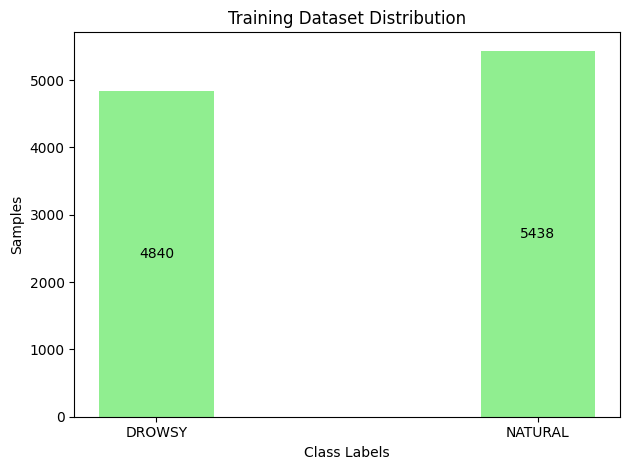

In [12]:
# Visualization of Training Statistics
# _, ax = plt.subplots()
# ax.set_facecolor('white')
bar = plt.bar(x=class_names, height=class_samples, width=0.3, color='lightgreen')
plt.bar_label(bar, label_type='center')
plt.xlabel('Class Labels')
plt.ylabel('Samples')
plt.title('Training Dataset Distribution')
plt.tight_layout()
plt.savefig('train_distribution.png')    
plt.show()

### Data Preprocessing & Augmentation

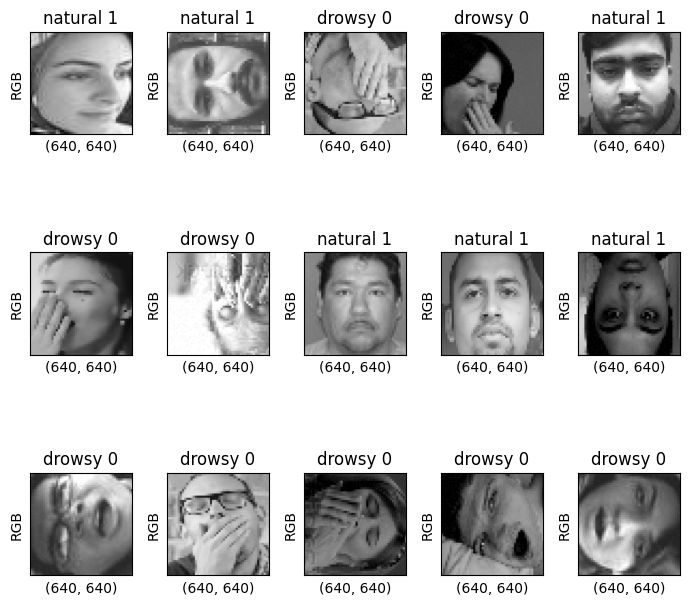

In [13]:
# Displaying Random Training Images Dimension
fig = plt.figure(figsize=(7, 7))
rows, columns = 3, 5

for i in range(1, rows*columns+1):
    fig.add_subplot(rows, columns, i)
    
    random_idx = torch.randint(0, len(train_data), size=(1,)).item()
    image, label = train_data[random_idx]
    
    plt.imshow(image)
    plt.title(f'{class_names[label].lower()} {label}')
    plt.ylabel(image.mode)
    plt.xlabel(image.size)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

> *First Compute Mean, Std Deviation of Train Image Pixels Using Sum & Square Method*

In [9]:
# train_stats_transform = T.Compose([
#     T.Resize((224, 224)),
#     T.ToTensor()
# ])

In [10]:
# train_data_stats = DataLoader(ImageFolder(root=train_data.root, transform=train_stats_transform), 
#                               batch_size=64, num_workers=4, 
#                               pin_memory=(device.type == 'cuda'), shuffle=False)

# channel_sum = torch.zeros(3, device=device)
# channel_sum_sq = torch.zeros(3, device=device)
# total_batches = 0
# total_pixels = 0

# for data, lbl in train_data_stats:
#     data = data.to(device, non_blocking=True)
#     channel_sum += torch.sum(data, dim=[0,2,3])
#     channel_sum_sq += torch.sum(data**2, dim=[0,2,3])
#     total_pixels += data.shape[0] * data.shape[2] * data.shape[3]
#     total_batches +=1

# mean = channel_sum / total_pixels
# meansq = channel_sum_sq / total_pixels
# variance = meansq - mean**2
# std = torch.sqrt(variance.clamp_min(0))

# print(f'Dataset Mean: {mean} and Std: {std}')
# print(f'Total Batches Processed: {total_batches}')
# print(f'Total Pixels: {total_pixels}')

In [51]:
num_batches = 161
# process_pixels = 515708928

# print("Expected Pixels:", len(train_data) * 224 * 224)
# print(f'Proceede Pixels: {process_pixels}')

In [17]:
mean = [0.4373, 0.4373, 0.4373]
std = [0.2449, 0.2449, 0.2449]

> *Training Random Geometric and Appearance Transformation & Augmentation*

***Experiment No.1***

In [18]:
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5),
    T.RandomRotation(degrees=(0,90)),
    T.ToTensor(),
    T.Normalize(mean, std)
])

In [52]:
train_loader = DataLoader(ImageFolder(root=train_data.root, transform=train_transform), batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=True)
size = train_loader.dataset
print(size)

Dataset ImageFolder
    Number of datapoints: 10278
    Root location: /kaggle/input/datasets/mirzaabubakarmughal/driver-fatigue-classification/train
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ColorJitter(brightness=(0.5, 1.5), contrast=(0.5, 1.5), saturation=(0.5, 1.5), hue=None)
               RandomRotation(degrees=[0.0, 90.0], interpolation=nearest, expand=False, fill=0)
               ToTensor()
               Normalize(mean=[0.4373, 0.4373, 0.4373], std=[0.2449, 0.2449, 0.2449])
           )


***Experiment No.2***

In [45]:
train_random_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomApply(torch.nn.ModuleList([
        T.RandomAdjustSharpness(sharpness_factor=2, p=0.5),
        T.RandomAutocontrast(p=0.5),
        T.RandomEqualize(p=0.3),
        T.RandAugment(),
    ]), p=0.5),
    T.ToTensor(),
    T.Normalize(mean, std)
])

In [49]:
train_random_loader = DataLoader(ImageFolder(root=train_data.root, transform=train_random_transform), batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=True)
print(train_loader.dataset)

Dataset ImageFolder
    Number of datapoints: 10278
    Root location: /kaggle/input/datasets/mirzaabubakarmughal/driver-fatigue-classification/train
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ColorJitter(brightness=(0.5, 1.5), contrast=(0.5, 1.5), saturation=(0.5, 1.5), hue=None)
               RandomRotation(degrees=[0.0, 90.0], interpolation=nearest, expand=False, fill=0)
               ToTensor()
               Normalize(mean=[0.4373, 0.4373, 0.4373], std=[0.2449, 0.2449, 0.2449])
           )


### Model Architecture Design

*CNN From Scratch*

In [29]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        
    def foward(input, self):
        return output

model = CNN().to(device)
print(model)

CNN()


*Hyperparameters*

In [ ]:
epochs = 20
batch_size = 64
criterion = nn.BCEWithLogitsLoss(reduction='None')
optimizer = optim.Adam(model.parameters(), lr=0.001)

### Model Training Pipeline

*First Time Training Loop*

In [ ]:
for epoch in range(epochs): 
    print(f'Epoch [{epoch+1}/{epochs}]') 
    
    run_loss = 0.0 
    correct = 0
    total = 0

    # train mode for batch normalize and dropout layers
    model.train() 
    
    for batch, (images, labels) in enumerate(train_loader): 
        images = images.to(device, non_blocking=True) 
        labels = labels.to(device, non_blocking=True).type(torch.float)
        
        # Forward pass
        outputs = model(images).reshape(-1)
        labels = labels.reshape(-1)
        loss = criterion(outputs, labels) 

        # Backward pass
        optimizer.zero_grad()
        loss.backward() 
        optimizer.step() 
        
        # Running Accuracy
        predictions = (outputs >= 0.0).float()
        batch_correct = (predictions == labels).sum().item()
        run_accuracy = batch_correct / labels.size(0)
        
        # Averaging
        run_loss += loss.item()
        correct += batch_correct
        total += labels.size(0)

        # Current Batch
        current = batch * batch_size + len(images) 

        # Each batch performance
        print(f'Loss: {loss.item():.4f}  Accuracy: {run_accuracy:.4f}  Batch: [{current:>5d}/{size:>5d}]') 

    # Entire Performance
    avg_loss = run_loss / num_batches
    avg_accuracy = (correct/total) * 100
    
    print(f'Training Average Accuracy: {(avg_accuracy):>0.1f}%  Training Average Loss: {avg_loss:>8f}\n')
print("Done!")

### Evaluation & Hyperparameter Tunning

In [14]:
# valid_transform = T.Compose([
#     T.Resize((224, 224))
#     T.ToTensor(),
#     T.Normalize(mean, std)
# ])

In [15]:
# valid_loader = DataLoader(ImageFolder(root=train_data.root, transform=valid_transform), 
#                          batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=False))

### Model Inference Pipeline

In [16]:
# test_transform = T.Compose([
#     T.Resize((224, 224))
#     T.ToTensor(),
#     T.Normalize(mean, std)
# ])

In [17]:
# test_loader = DataLoader(ImageFolder(root=train_data.root, transform=test_transform), 
#                          batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=False))

### Model Deployment MLOps